# Imports

In [1]:
# Get imports and functions needed
%run BaseFiles/Imports.ipynb
%run BaseFiles/Functions.ipynb

# Set global variables
colour1 = "royalblue"
colour2 = "red"


/home/rahyndman/miniforge3/envs/sunpyVenv/lib/python3.14/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
2026-10-23 11:44:17 - spiceypy.utils.libspicehelper - INFO: Using fallback library next to module: /net/maedoc.ap.dias.ie/maedoc/home_cr/rahyndman/miniforge3/envs/sunpyVenv/lib/python3.14/site-packages/spiceypy/utils/libcspice.so


# Read data from files

In [2]:
# Places to get and save files
DataDirectory = "Data/windData/"
dataName = "wind_min_b"
PlotDirectory = "Plots/WindYearlyPlots/"

# Variables
DataSource = "Wind"
Start  = "1996-01-01 00:00"
End = "1996-02-01 00:00"

#Separated by data source as files may have different file name conventions
if DataSource == "Wind": # If WIND data
    YearlyRange = Yearly(Start, End, frequency = 'MS') #Get range of dates needed # changed to monthly
    print(YearlyRange)
    dataTimeSerieses = [] # empty array for data
    # StartAndEnd = [] # empty array for start and end times
    for i in range(len(YearlyRange)-1): # for each date range in time range needed
        StartDate = YearlyRange[i] # first file in range
        EndDate = YearlyRange[i][0:6] + "31" # last file in range
        # print(StartDate, EndDate)
        # DateRange = ReadDates(StartDate, EndDate) # get date range
        dataFound = FindDataWind(DataDirectory, dataName, StartDate, EndDate) # find data
        dataTS = dfToSeries(dataFound) # convert to timeseries
        dataTS = AddTotVsw(dataTS) # add totvsw
        # dataTS = AddBMag(dataTS) # add bmag
        # dataTS = AddLogBMag(dataTS) 
        # dataTS = AddLogBX(dataTS)
        dataTimeSerieses.append(dataTS) # add to data array
        # StartAndEnd.append([StartDate, EndDate]) # add start and end dates to times array

else: # if not wind (or other coded sources)
    print("Data source not known") # give error message

['19960101', '19960201']


In [3]:
import pandas as pd

data = {
  "testValue": [0, 25, 125, 225, 325, 400, 425, 450, 525, np.nan]
  #"duration": [50, 40, 45]
}

#load data into a DataFrame object:
df = pd.DataFrame(data)

print(df) 

thresMax = 450
thresMin = 400
# TestValue = [0, 25, 125, 225, 325, 400, 425, 450, 525, np.nan]
# TestValue = pd.DataFrame(TestValue)
maskFirst = df["testValue"].between(thresMin, thresMax)
print(maskFirst)


   testValue
0        0.0
1       25.0
2      125.0
3      225.0
4      325.0
5      400.0
6      425.0
7      450.0
8      525.0
9        NaN
0    False
1    False
2    False
3    False
4    False
5     True
6     True
7     True
8    False
9    False
Name: testValue, dtype: bool


# Method 1 : Includes values on threshold

In [64]:
def Method1Calc(Data, Thres, AbsThres, Variable = "TotVsw"):
    maskFirst = Data.to_dataframe()[Variable].between(Thres-AbsThres, Thres+AbsThres) # get true/false array of data based on condition of values being between the threshold values

    StartsPossible = [] # empty array for possible start times
    EndsPossible = [] # empty array for possible end times
    Starts = [] # empty array for nan-filtered start times
    Ends = [] # empty array for nan-filtered end times

    for x in range(len(maskFirst)): # for each point in the dataset
        # print(x, len(maskFirst))
        # if x+1 > len(maskFirst): # if the next point is past the end of the dataset
        #     if maskFirst.values[x] == True: # and this point is in the threshold
        #         EndsPossible.append(maskFirst.index[x]) # add the time to the EndsPossible array
        #     break # then stop the for loop
        if maskFirst.values[x] == True and maskFirst.values[x-1] == False and Data.to_dataframe()[Variable].values[x-1] != np.nan: # if the point exists between the thresholds and the previous point does not, AND the previous point is not a gap
            # start = maskFirst.index[x] # set start variable to the last timestamp that was within the threshold
            StartsPossible.append(maskFirst.index[x]) # add the time to the StartsPossible array
        # if maskFirst.values[x] == True and maskFirst.values[x-1] == True: # if the point exists between the thresholds and the previous point does too
        #     # print("Middle") # print middle (this is for checking the code is doing what we think it is)
        #     pass
        if maskFirst.values[x] == True and maskFirst.values[x+1] == False and Data.to_dataframe()[Variable].values[x+1] != np.nan: # if the point exists between the thresholds and the next point does not, AND the next point is not a gap
            # end = maskFirst.index[x] # set the end variable to the last timestamp that was within the threshold
            EndsPossible.append(maskFirst.index[x]) #  add the time to the EndsPossible array
        # elif maskFirst.values[x] == False: # else if the point does not exist between the thresholds
        #     # print("Not in threshold") # print not in threshold (this is for checking the code is doing what we think it is)

    for y in range(len(StartsPossible)):    
        CheckData = Data.to_dataframe().truncate(StartsPossible[y], EndsPossible[y])
        # print(CheckData[Variable].notna().sum(), CheckData[Variable].isna().sum())
        if CheckData[Variable].notna().sum() >= CheckData[Variable].isna().sum(): #if the amount of non-nans in the steadiness threshold is equal or larger than the amount of nans
            Starts.append(StartsPossible[y]) #then save the start and end times
            Ends.append(EndsPossible[y])


    return StartsPossible, EndsPossible, Starts, Ends

In [68]:
def Method1Calc(Data, Thres, AbsThres, Variable = "TotVsw"):
    maskFirst = Data.to_dataframe()[Variable].between(Thres-AbsThres, Thres+AbsThres) # get true/false array of data based on condition of values being between the threshold values

    StartsPossible = [] # empty array for possible start times
    EndsPossible = [] # empty array for possible end times
    Starts = [] # empty array for nan-filtered start times
    Ends = [] # empty array for nan-filtered end times

    for x in range(len(maskFirst)): # for each point in the dataset
        if x+1 == len(maskFirst): # if the next point is past the end of the dataset
            if maskFirst.values[x] == True: # and this point is in the threshold
                EndsPossible.append(maskFirst.index[x]) # add the time to the EndsPossible array
            break # then stop the for loop

        current_is_true = maskFirst.values[x] == True
        previous_is_false = maskFirst.values[x-1] == False
        next_is_false = maskFirst.values[x+1] == False

        previous_is_nan = np.isnan(Data.to_dataframe()[Variable].values[x-1])
        next_is_nan = np.isnan(Data.to_dataframe()[Variable].values[x+1])
        print(previous_is_nan)

        if current_is_true and previous_is_false and not previous_is_nan:
            StartsPossible.append(maskFirst.index[x]) # add the time to the StartsPossible array

        if current_is_true and next_is_false and not next_is_nan:
            EndsPossible.append(maskFirst.index[x]) #  add the time to the EndsPossible array


    print(len(StartsPossible))
    print(len(EndsPossible))
    for y in range(len(StartsPossible)):  

        if StartsPossible[y] == EndsPossible[y] or EndsPossible[y] < StartsPossible[y]:
            continue 
        CheckData = Data.to_dataframe().truncate(StartsPossible[y], EndsPossible[y])
        # print(CheckData[Variable].notna().sum(), CheckData[Variable].isna().sum())
        if CheckData[Variable].notna().sum() >= CheckData[Variable].isna().sum(): #if the amount of non-nans in the steadiness threshold is equal or larger than the amount of nans
            Starts.append(StartsPossible[y]) #then save the start and end times
            Ends.append(EndsPossible[y])


    return StartsPossible, EndsPossible, Starts, Ends


def Method1Plot(Timestart, Timeend, Starts, Ends, Thres, AbsThres, Title = "Total solar wind speed time series", YLabel="Total solar wind speed, km/s", Color = "royalblue", Alpha = 0.05):
    plt.hlines(Thres + AbsThres, xmin = Timestart, xmax = Timeend, color=Color) # plot horizontal lines showing threshold values
    plt.hlines(Thres - AbsThres, xmin = Timestart, xmax = Timeend, color=Color)
    for y in range(len(Starts)): # for each start date (and hopefully each steadiness period)
        plt.axvspan(Starts[y], Ends[y], color = Color, alpha = Alpha) # plot vertical highlighted regions to show where the regions of steadiness are
        # plt.axvspan(starts[y], ends[y], ymin = FirstBaseValue-AbsoluteThreshold, ymax = FirstBaseValue+AbsoluteThreshold, color = "green", alpha = 0.1)

    #General plot settings
    plt.title(Title)
    plt.xlabel("Time")
    plt.ylabel(YLabel)



def Distrib(Starts, Ends, Bins = 50, Variable = "TotVsw", Color="royalblue", Alpha = 0.5):
    # Bins = np.arange(0, 16000, 500)
    tau = []
    for x in range(len(Starts)): # for the length of the Starts array (hopefully equal to the length of the Ends array)
        tau.append(Ends[x]-Starts[x]) # add the duration of each steadiness period
    # print(tau)
    tauInS = []
    for y in range(len(tau)):
        tauInS.append(tau[y].total_seconds()) # change the durations to be in seconds
    # plt.hist(tauInS, bins = Bins, color= Color, alpha=Alpha) # plot the time durations in a histogram
    plt.hist(tauInS, bins = Bins, color= Color, alpha=Alpha) # plot the time durations in a histogram

    #General plot settings
    plt.title("Steadiness timeframes for " + str(Variable))
    plt.xlabel("Steadiness timeframe durations, s")
    plt.ylabel("Frequency")




File not saved
False
True
True
True
False
False
True
False
False
False
False
False
False
False
False
False
False
False
False
True
True
True
True
True
True
False
False
True
False
False
False
False
False
False
True
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
True
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
True
True
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
False
True
False
False
True
False
False
False


IndexError: list index out of range

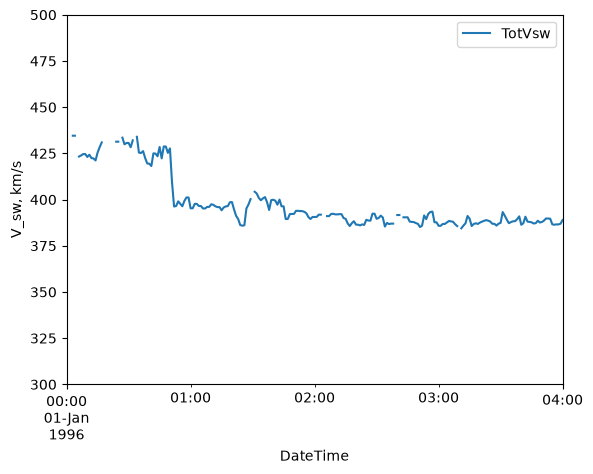

In [69]:
timestart = "1996-01-01 00:00"
timeend = "1996-01-01 04:00"
# timestart = "1996-01-01 00:00"
# timeend = "1996-01-03 00:00"
variable = "TotVsw"
thres1 = 390
absThres1 = 5 # 385-395
color1 = "royalblue"

thres2 = 425
absThres2 = 5 # 395-405
color2 = "red"

PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [300, 500])
plt.ylabel("V_sw, km/s")

startsP1, endsP1, starts1, ends1 = Method1Calc(dataTimeSerieses[0], thres1, absThres1)
startsP2, endsP2, starts2, ends2 = Method1Calc(dataTimeSerieses[0], thres2, absThres2)

# print(len(startsP1), len(starts1))
# print(len(endsP1), len(ends1))
# print(len(startsP2), len(starts2))
# print(len(endsP2), len(ends2))
Method1Plot(timestart, timeend, starts1, ends1, thres1, absThres1, Color=color1)
Method1Plot(timestart, timeend, starts2, ends2, thres2, absThres2, Color=color2)

plt.scatter(startsP1, dataTimeSerieses[0].to_dataframe()["TotVsw"][np.array(startsP1)], marker=".")
plt.scatter(endsP1, dataTimeSerieses[0].to_dataframe()["TotVsw"][np.array(endsP1)], marker=".", color="red")


# # plt.legend(["Steadiness: " + str(thres1-absThres1) + "-"+ str(thres1+absThres1), "Steadiness: " + str(thres2-absThres2) + "-"+ str(thres2+absThres2)])
# # plt.legend()

# print("Caption: Section of time series of solar wind speed with highlighted times that the values stay within the first ("+ str(thres1-absThres1) + "-" + str(thres1+absThres1)+"km/s, "+ color1+")\n and second ("+ str(thres2-absThres2) + "-" + str(thres2+absThres2)+"km/s, "+ color2+") threshold. Highlighted sections are coloured coded to show each threshold.")
# plt.show()

# ############################
# Distrib(starts1, ends1, Color=color1)
# Distrib(starts2, ends2, Color=color2)
# plt.yscale("log")
# print("Caption: Histogram of steadiness timeframes for TotVsw for the first ("+ str(thres1-absThres1) + "-" + str(thres1+absThres1)+"km/s, "+ colour1+") \nand second ("+ str(thres2-absThres2) + "-" + str(thres2+absThres2)+"km/s, "+ colour2+") threshold for first month of 1996.")


In [6]:
print(startsP1[3:5])
print(endsP1[3:5])

[Timestamp('1996-01-01 01:46:00'), Timestamp('1996-01-01 02:06:00')]
[Timestamp('1996-01-01 02:03:00'), Timestamp('1996-01-01 02:38:00')]


In [7]:
print(dataTimeSerieses[0].to_dataframe()["TotVsw"].index[120:150])
print(dataTimeSerieses[0].to_dataframe()["TotVsw"].values[120:150])
print(dataTimeSerieses[0].to_dataframe()["TotVsw"].values[124])
dataTimeSerieses[0].to_dataframe()["TotVsw"].values[124]


DatetimeIndex(['1996-01-01 02:00:00', '1996-01-01 02:01:00',
               '1996-01-01 02:02:00', '1996-01-01 02:03:00',
               '1996-01-01 02:04:00', '1996-01-01 02:05:00',
               '1996-01-01 02:06:00', '1996-01-01 02:07:00',
               '1996-01-01 02:08:00', '1996-01-01 02:09:00',
               '1996-01-01 02:10:00', '1996-01-01 02:11:00',
               '1996-01-01 02:12:00', '1996-01-01 02:13:00',
               '1996-01-01 02:14:00', '1996-01-01 02:15:00',
               '1996-01-01 02:16:00', '1996-01-01 02:17:00',
               '1996-01-01 02:18:00', '1996-01-01 02:19:00',
               '1996-01-01 02:20:00', '1996-01-01 02:21:00',
               '1996-01-01 02:22:00', '1996-01-01 02:23:00',
               '1996-01-01 02:24:00', '1996-01-01 02:25:00',
               '1996-01-01 02:26:00', '1996-01-01 02:27:00',
               '1996-01-01 02:28:00', '1996-01-01 02:29:00'],
              dtype='datetime64[us]', name='DateTime', freq=None)
[390.59754223 390.

np.float64(nan)

# Method 2: does not include values on threshold

- So find timespan (if next one equals nan then move to next one)
    - Then have counters for how many nans (or count after with package)
    - and counters for how many non-nans
    - if nansCount > notNansCount:
        - then don’t add to list of timespans

In [8]:
thresMax = 450
thresMin = 400

TestValue = [0, 25, 125, 225, 325, 400, 425, 450, 525, np.nan]
for i in TestValue:
    if i >= thresMax or i <= thresMin:
        print("Outside Threshold")
    else:
        print("Inside Threshold")


Outside Threshold
Outside Threshold
Outside Threshold
Outside Threshold
Outside Threshold
Outside Threshold
Inside Threshold
Outside Threshold
Outside Threshold
Inside Threshold


In [9]:
def Method2Calc(Timestart, Timeend, Data, RelThres, Variable = "TotVsw"):
    DataShort = Data.truncate(Timestart, Timeend) # Truncate the dataframe for the start and end times
    DataDf = DataShort.to_dataframe() # convert to dataframe

    Starts = [] # create empty array for start times
    Ends = [] # create empty array for end times
    PointTimes = [] # create empty array for time of each measurement
    PointValues = [] # create empty array for value of each measurement
    ThresMaxs = [] # create empty array for time of each measurement
    ThresMins = [] # create empty array for value of each measurement
    PointNanCounter = 0  # create counter for Nans
  
    for i in range(0, len(DataDf[Variable])):
        if str(DataDf[Variable].values[i]) == "nan": # if point has nan values
            # print("Nan")
            PointNanCounter += 1 # add one to the nan counter and move on to the next point

        else:
            # GapNanCounter = 0
            # NotNan = 0
            # NotNan += 1 # add one to the NotNan counter since the data point itself has a value
            Thres = DataDf[Variable].values[i] # set base value for thresholds
            thresMax = Thres + (Thres*RelThres) # max value in threshold
            thresMin = Thres - (Thres*RelThres) # min value in threshold
            ThresMaxs.append(thresMax)
            ThresMins.append(thresMin)
            PointValues.append(DataDf[Variable].values[i]) # add time of measurement to points array
            PointTimes.append(DataDf[Variable].index[i]) # add time of measurement to points array
            # print(Thres)
            # print("Base value = " + str(Thres) + ", ThresMax = " + str(thresMax)+ ", ThresMin = " + str(thresMin)) # print chosen values

            for j in range(1, i): # for values BEFORE this one in the timeseries
                # print("i:" + str(i))
                # print("j:" + str(j))
                if i-j <= 1: # check if you've reached the beginning of your dataset
                    # print("Start of values")
                    # Starts.append(DataDf[Variable].index[0]) # set the start time of this steadiness timeframe to the start timestamp of your dataset
                    start = DataDf[Variable].index[0] # set the start variable of this steadiness timeframe to the start timestamp of your dataset

                    break # end search
                else:
                    if DataDf[Variable].values[i-j] >= thresMax or DataDf[Variable].values[i-j] <= thresMin: #if the value is outside the threshold range
                        # print("Closest neighbour = " + str(j) + " away.") # choose it as the closest neighbour
                        # Starts.append(DataDf[Variable].index[i-j+1]) # set the start time to the last timestamp that was within the threshold
                        start = DataDf[Variable].index[i-j+1] # set start variable to the last timestamp that was within the threshold

                        # if DataDf[Variable].values[i-j] == np.nan: # in the case that this is a data gap (np.nan) add one to the counter
                        #     print("Nan Found")
                        #     GapNanCounter += 1
                        # else:
                        #     print("Not nan")
                        #     NotNan += 1
                        break # end search
                    # else:
                    #     print("Still looking.") # print that you're still looking

            for k in range(1, len(DataDf[Variable])): # for values AFTER this one in the timeseries
                # print("i:" + str(i))
                # print("k:" + str(k))
                # print("i+k:" + str(i+k))
                if i+k >= len(DataDf[Variable]): # check if you've reached the end of your dataset
                    # print("End of values")
                    # Ends.append(DataDf[Variable].index[-1]) # set the ends time of this steadiness timeframe to the end timestamp of your dataset
                    end = DataDf[Variable].index[-1] # set the ends variable of this steadiness timeframe to the end timestamp of your dataset
                    
                    # if DataDf[Variable].values[i-j] == np.nan: # in the case that this is a data gap (np.nan) add one to the counter
                    #     print("Nan Found")
                    #     GapNanCounter += 1
                    # else:
                    #     print("Not nan")
                    #     NotNan += 1

                    break # end search
                else:
                    if DataDf[Variable].values[i+k] >= thresMax or DataDf[Variable].values[i+k] <= thresMin: #if the value is outside the threshold range
                        # print("Closest neighbour = " + str(k) + " away.") # choose it as the closest neighbour
                        # Ends.append(DataDf[Variable].index[i+k-1]) # set the end time to  the last timestamp that was within the threshold
                        end = DataDf[Variable].index[i+k-1] # set the end variable to the last timestamp that was within the threshold
                        break # end search
                    # else:
                    #     print("Still looking.") # print that you're still looking
    
            CheckData = dataTimeSerieses[0].to_dataframe().truncate(start, end)
            if CheckData[Variable].notna().sum() >= CheckData[Variable].isna().sum(): #if the amount of non-nans in the steadiness threshold is equal or larger than the amount of nans
                Starts.append(start) #then save the start and end times
                Ends.append(end)

    # if NotNan >= GapNanCounter:
    #     print("Enough data found")
    #     EnoughData.append(True)
    # else:
    #     print("Not enough data found")
    #     EnoughData.append(False)
    return Starts, Ends, PointValues, PointTimes, ThresMaxs, ThresMins


def Method2Plot(Starts, Ends, PointValues, PointTimes, ThresMaxs, ThresMins, NoOfSections= 10,  Colors=[], All = False, Title = "Total solar wind speed time series", YLabel="Total solar wind speed, km/s", Color = "red", Alpha = 0.05):
    if All == True:
        for i in range(len(Starts)):
            plt.axvspan(Starts[i], Ends[i], color = Color, alpha = Alpha)
    else:
        Range = np.arange(0, len(Starts), round(len(Starts)/NoOfSections))
        j = 0
        for i in Range:
            plt.axvspan(Starts[i], Ends[i], color = Color, alpha = Alpha, zorder=1)
            plt.scatter(PointTimes[i], PointValues[i], color = Color, zorder=3, s=15)
            plt.vlines(Starts[i], ThresMins[i], ThresMaxs[i], color = Color, zorder=2)
            plt.vlines(Ends[i], ThresMins[i], ThresMaxs[i], color = Color, zorder=2)
            plt.hlines(PointValues[i], Starts[i], Ends[i], color = Color, zorder=2)
            j += 1
    # print(len(start))
    # print(len(end))
    # plt.hlines(thresMin, xmin = timestart, xmax = timeend, color=colour1)
    # plt.hlines(thresMax - AbsoluteThreshold, xmin = timestart, xmax = timeend, color=colour1)

    #General plot settings
    plt.title(Title)
    plt.xlabel("Time")
    plt.ylabel(YLabel)


File not saved
Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point). 


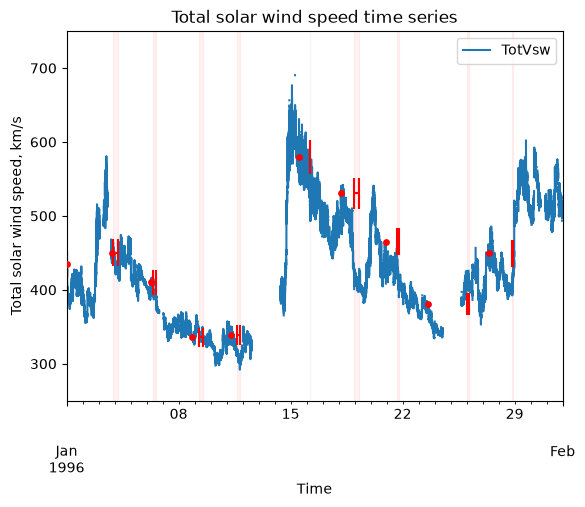

In [10]:
timestart = "1996-01-01 00:00"
timeend = "1996-02-01 00:00"
xlimS = timestart #"1996-01-01 00:00"
xlimE = timeend #"1996-01-01 04:00"
ylimS = 350
ylimE = 550
# testingSeries = dataTimeSerieses[0].truncate(timestart, timeend)
# Thres = 400
relThres = 0.04

# colors = ["red", "orange", "goldenrod", "green", "lightblue", "navy", "purple", "pink", "grey", "black", "white"]

# PlotVsw(testingSeries, Columns=["TotVsw"], XLim =[xlimS, xlimE], YLim = [ylimS,ylimE])
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [250,750])
startsM2, endsM2, pointvaluesM2, pointtimesM2, thresMaxsM2, thresMinsM2 = Method2Calc(timestart, timeend, dataTimeSerieses[0], relThres)
Method2Plot(startsM2, endsM2, pointvaluesM2, pointtimesM2, thresMaxsM2, thresMinsM2)

print("Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point). ")


# Check that nans thing is right

In [11]:
# BEFORE NAN FIX
# print(len(startsM2)) # 34436
# print(len(endsM2)) # 34436

# AFTER NAN FIX
# print(len(startsM2)) # 32448
# print(len(endsM2)) # 32448

difference = 34436-32448
print("Total timespans removed = " + str(difference))
print("Percentance difference = " + str(round(difference/34436 * 100, 2)) + " %")

Total timespans removed = 1988
Percentance difference = 5.77 %


File not saved
Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).


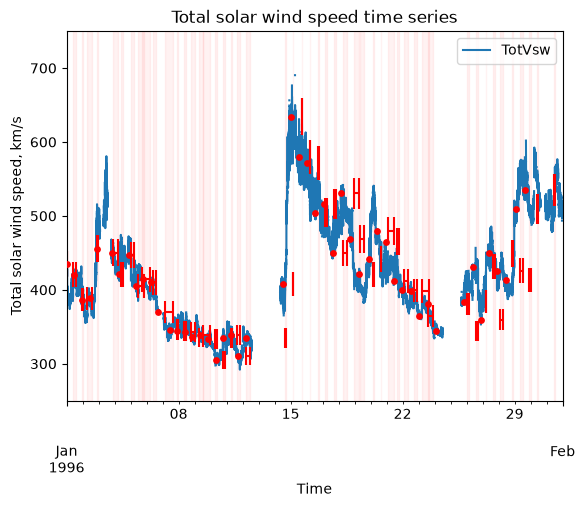

File not saved
Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).


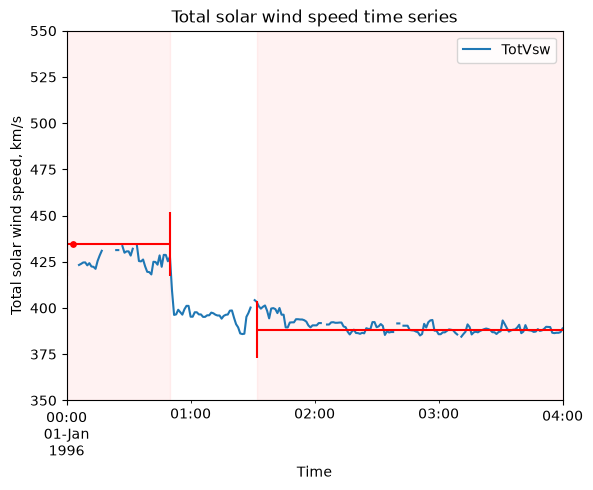

In [12]:
######### Whole month plot ###########
# Just plotting, post-calculations
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [250,750])
Method2Plot(startsM2, endsM2, pointvaluesM2, pointtimesM2, thresMaxsM2, thresMinsM2, NoOfSections=50)
print("Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).")
plt.show()

######### Zoom into part of the plot ###########
# Just plotting, post-calculations, zoom
# ZoomStart = "1996-01-01 00:00"
# ZoomEnd = "1996-01-03 00:00"
ZoomStart = "1996-01-01 00:00"
ZoomEnd = "1996-01-01 04:00"
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [ylimS,ylimE])
Method2Plot(startsM2, endsM2, pointvaluesM2, pointtimesM2, thresMaxsM2, thresMinsM2, NoOfSections=100)
plt.xlim(ZoomStart, ZoomEnd)
print("Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).")


# Save data so no recalculation is done at the moment

In [13]:
# import datetime as dt

# ResultsSaved = pd.DataFrame({"Starts":startsM2, "Ends":endsM2, "PointValues":pointvaluesM2, "PointTimes": pointtimesM2, "ThresMaxs":thresMaxsM2, "ThresMins":thresMinsM2})
# ResultsSaved.to_csv("ResultsSaved" + str(dt.datetime.now().date()) + ".csv", index=False)

# Plotting

File not saved
Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).


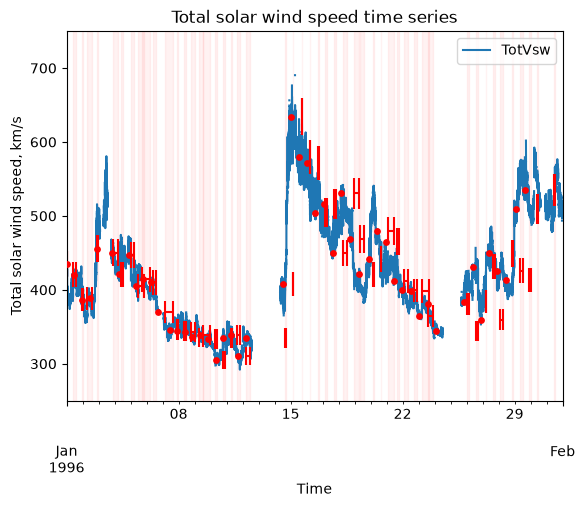

File not saved
Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).


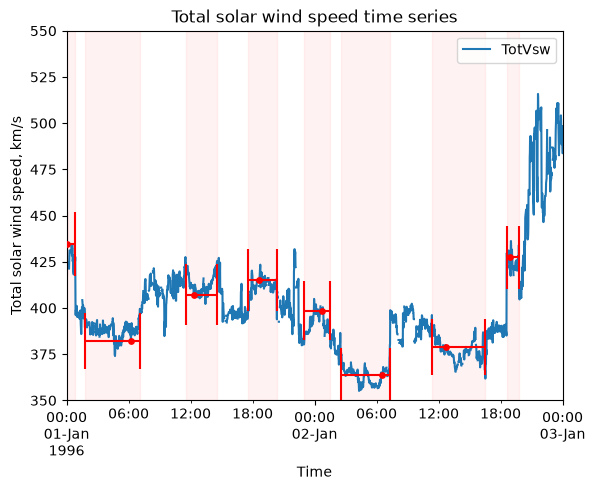

In [14]:
# Read saved file
File = pd.read_csv("ResultsSaved2026-10-19.csv")
# print(File.Ends)


######### Whole month plot ###########
# Just plotting, post-calculations
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [250,750])
Method2Plot(startsM2, endsM2, pointvaluesM2, pointtimesM2, thresMaxsM2, thresMinsM2, NoOfSections=50)
# Method2Plot(File.Starts, File.Ends, File.PointValues, File.PointTimes, File.ThresMaxs, File.ThresMins, NoOfSections=50)
print("Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).")
plt.show()

######### Zoom into part of the plot ###########
# Just plotting, post-calculations, zoom
ZoomStart = "1996-01-01 00:00"
ZoomEnd = "1996-01-03 00:00"
# ZoomStart = "1996-01-01 00:00"
# ZoomEnd = "1996-01-01 04:00"
PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [ylimS,ylimE])
# Method2Plot(startsM2, endsM2, pointvaluesM2, pointtimesM2, thresMaxsM2, thresMinsM2, NoOfSections=100)
Method2Plot(File.Starts, File.Ends, File.PointValues, File.PointTimes, File.ThresMaxs, File.ThresMins, NoOfSections=100)
plt.xlim(ZoomStart, ZoomEnd)
print("Caption: Time series of solar wind speed with highlighted times that the values remain steady for (relative to each data point).")


Caption: Histogram of steadiness timeframes for TotVsw for Method 2.


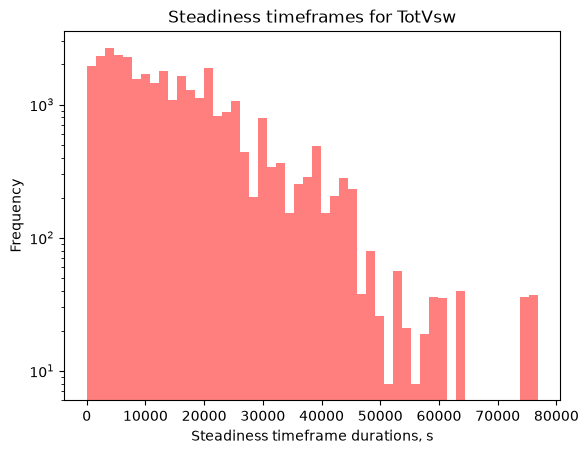

In [15]:
############################
Distrib(startsM2, endsM2, Color="red")
plt.yscale("log")
print("Caption: Histogram of steadiness timeframes for TotVsw for Method 2.")


In [16]:
print(testingSeries.to_dataframe()["TotVsw"].index[0])
print(testingSeries.to_dataframe()["TotVsw"].index[-1])

print(testingSeries.to_dataframe()["TotVsw"].values[3])
print(testingSeries.to_dataframe()["TotVsw"].values[2])
print(testingSeries.to_dataframe()["TotVsw"].values[1])
print("After")
print(testingSeries.to_dataframe()["TotVsw"].values[3])
print(testingSeries.to_dataframe()["TotVsw"].values[4])
print(testingSeries.to_dataframe()["TotVsw"].values[5])
print(testingSeries.to_dataframe()["TotVsw"].values[6])
print(testingSeries.to_dataframe()["TotVsw"].values[7])
print(testingSeries.to_dataframe()["TotVsw"].values[8])

basevalue = testingSeries.to_dataframe()["TotVsw"].values[3] # set base value
thresMax = basevalue + (basevalue*RelativeThreshold) # add threshold
thresMin = basevalue - (basevalue*RelativeThreshold) # minus threshold
print(basevalue, thresMax, thresMin)

for checking in range(0,55):
    if testingSeries.to_dataframe()["TotVsw"].values[checking] >= thresMax or testingSeries.to_dataframe()["TotVsw"].values[checking] <= thresMin:
        print("Yes")
        print(checking)
    else:
        print(checking)
        print(testingSeries.to_dataframe()["TotVsw"].values[checking])
        print("No")

print("start")
print(start)
print(basetime)
print(end)
print(len(start))
print(len(basetime))
print(len(end))

NameError: name 'testingSeries' is not defined

In [ ]:
print(testingSeries.to_dataframe()["TotVsw"].index)

DatetimeIndex(['1996-01-01 00:00:00', '1996-01-01 00:01:00',
               '1996-01-01 00:02:00', '1996-01-01 00:03:00',
               '1996-01-01 00:04:00', '1996-01-01 00:05:00',
               '1996-01-01 00:06:00', '1996-01-01 00:07:00',
               '1996-01-01 00:08:00', '1996-01-01 00:09:00',
               ...
               '1996-01-02 23:51:00', '1996-01-02 23:52:00',
               '1996-01-02 23:53:00', '1996-01-02 23:54:00',
               '1996-01-02 23:55:00', '1996-01-02 23:56:00',
               '1996-01-02 23:57:00', '1996-01-02 23:58:00',
               '1996-01-02 23:59:00', '1996-01-03 00:00:00'],
              dtype='datetime64[us]', name='DateTime', length=2881, freq=None)


File not saved


IndexError: list index out of range

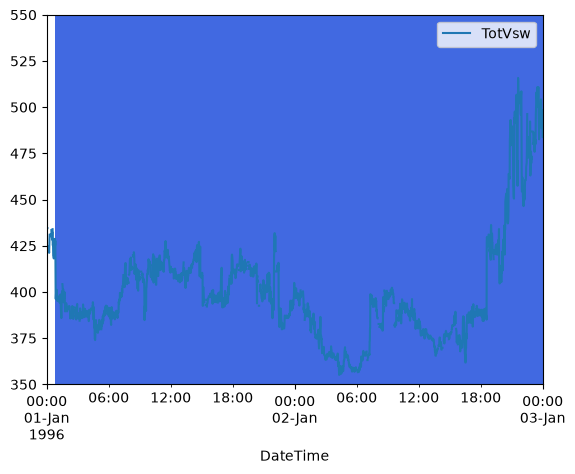

In [ ]:
timestart = "1996-01-01 00:00"
timeend = "1996-01-03 00:00"
xlimS = timestart #"1996-01-01 00:00"
xlimE = timeend #"1996-01-01 04:00"
ylimS = 350
ylimE = 550

testingSeries = dataTimeSerieses[0].truncate(timestart, timeend)

# PlotVsw(dataTimeSerieses[0], Columns=["TotVsw"], XLim =[timestart, timeend], YLim = [200,800])
PlotVsw(testingSeries, Columns=["TotVsw"], XLim =[xlimS, xlimE], YLim = [ylimS,ylimE])

Alpha = 0.1
RelativeThreshold = 0.05

from datetime import datetime, timedelta

tooShort = 0

for a in range(len(start)):
    # print(len(start))
    # print(len(end))
    # print(a)
    # print(a*10)

    if end[a] - start[a] < timedelta(minutes=60):
        tooShort += 1
    elif a <= len(start):
        plt.axvspan(start[a], end[a], color = colour1, alpha = Alpha)
    else:
        break

# plt.hlines(thresMin, xmin = timestart, xmax = timeend, color=colour1)
# plt.hlines(thresMax - AbsoluteThreshold, xmin = timestart, xmax = timeend, color=colour1)


#General plot settings
plt.title("Total solar wind speed time series")
plt.xlabel("Time")
plt.ylabel("Total solar wind speed, km/s")
# print("Caption: Time series of solar wind speed with highlighted times that the values stay within the first ("+ str(FirstBaseValue-AbsoluteThreshold) + "-" + str(FirstBaseValue+AbsoluteThreshold)+"km/s, "+ colour1+")\n and second ("+ str(SecondBaseValue-AbsoluteThreshold) + "-" + str(SecondBaseValue+AbsoluteThreshold)+"km/s, "+ colour2+") threshold. Highlighted sections are coloured coded to show each threshold.")

# New version saved

# Changepoint detection method

In [ ]:
def CUSUM(y, c, var):
    n = len(y)
    C_max = 0
    Tau_hat = 0
    S_n = sum(y)
    S = 0

    AllScores = []
    
    for t in range(1, n-1):
        S = S + y[t]
        ybar_1t = S/t
        ybar_t1n = (S_n-S)/(n-t)
        C2_t = (t*(n-t)/n)*(ybar_1t-ybar_t1n)**2
        AllScores.append(C2_t/var)
        if C2_t > C_max:
            C_max = C2_t
            Tau_hat = t

    if C_max/var > c:
        return Tau_hat, C_max, AllScores
    else:
        Null = np.nan
        return Null, C_max, AllScores

1503.5124653739615
3 5379.632675438596
150
[np.float64(0.050410222333585525), np.float64(0.14789002039220306), np.float64(3.578043281537108), np.float64(2.646959658638681), np.float64(1.7920187683451172), np.float64(1.2591410590878134), np.float64(1.0535480036721816), np.float64(0.7908514570430895), np.float64(0.5526489730009464), np.float64(0.44448004385749434), np.float64(2.3819060772323954), np.float64(2.0705237517950312), np.float64(0.6196129649197994), np.float64(0.4763662243484192), np.float64(0.4245082920633983), np.float64(0.2940665179843566), np.float64(0.19571919797603912)]


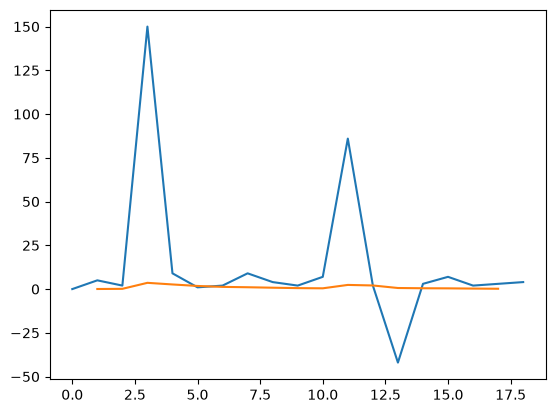

In [ ]:
y = [0,5,2,150,9,1,2,9,4,2,7,86,2,-42,3,7,2,3,4]
x = np.arange(0, len(y))
plt.plot(x, y)
Tau_hat, C_max, AllScores = CUSUM(y, 2, np.var(y))
print(np.var(y))

print(Tau_hat, C_max)
print(y[Tau_hat])

print(AllScores)

plt.plot(x[1:-1], AllScores)

In [ ]:
y = dataTimeSerieses[0].to_dataframe()["TotVsw"].values
print(y)

[         nan          nan          nan ... 506.60268456 507.30099547
 507.1003944 ]


5618.511653335351
15121 61653518.234834775
320.3476080759774
[np.float64(0.01924283440319775), np.float64(0.008052029128337673), np.float64(0.005043761229443229), np.float64(0.004153332275868026), np.float64(0.003672904622925048), np.float64(0.0024342698443808033), np.float64(0.002133540669757797), np.float64(0.0012368574631976843), np.float64(0.0006116127810051247), np.float64(0.00011794824759632048), np.float64(0.00024289294219095376), np.float64(0.0009742770449351044), np.float64(0.003032946329688361), np.float64(0.0061809307468039115), np.float64(0.010127893248885746), np.float64(0.016542095099099485), np.float64(0.02054036554663206), np.float64(0.02548592639417227), np.float64(0.030695186954708225), np.float64(0.03358253581488468), np.float64(0.04072883535502441), np.float64(0.0506679379983535), np.float64(0.049991698828173975), np.float64(0.04915002209763837), np.float64(0.04960238386905506), np.float64(0.04581092394205289), np.float64(0.03929243612175397), np.float64(0.033358578

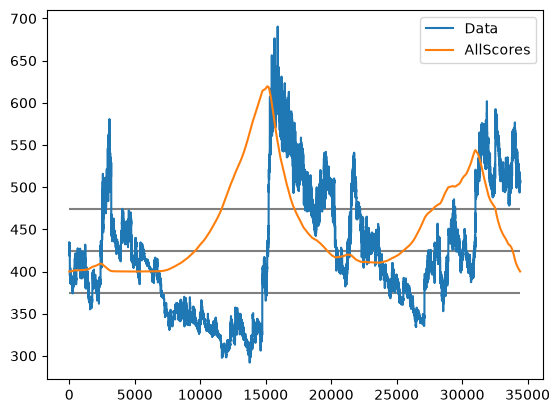

In [ ]:
y = dataTimeSerieses[0].to_dataframe()["TotVsw"].values
x = np.arange(0, len(y))

# plt.plot(x, y, label="Data")

cleanedList = [x for x in y if str(x) != 'nan']
print(np.var(cleanedList))
x = np.arange(0, len(cleanedList))

plt.plot(x, cleanedList, label="Data")
Tau_hat, C_max, AllScores = CUSUM(cleanedList, 50, np.var(cleanedList))

plt.hlines(np.mean(cleanedList), 0, len(x), color="grey", zorder=0)
plt.hlines(np.mean(cleanedList)+50, 0, len(x), color="grey", zorder=0)
plt.hlines(np.mean(cleanedList)-50, 0, len(x), color="grey", zorder=0)

print(Tau_hat, C_max)
print(y[Tau_hat])

print(AllScores)

AllScoresAdj = []
for a in AllScores:
    AllScoresAdj.append((a/50)+400)

plt.plot(x[1:-1], AllScores, label="AllScores")
# plt.plot(x[1:-1], AllScoresAdj, label="AllScores")

plt.legend()